# Лабораторна робота № 1
## Дослідження процесів дискретизації, квантування сигналів та ефекту аліасингу

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy, SciPy (`scipy.signal`, `scipy.fft`), Matplotlib

## 1. Мета роботи

Дослідити перетворення неперервного сигналу в цифрову форму (дискретизація за часом і квантування за рівнем), експериментально перевірити теорему відліків Котельникова–Шеннона–Найквіста, дослідити прояв аліасингу в часовій та частотній областях, розрахувати похибку квантування і співвідношення сигнал/шум (SNR), а також оцінити вплив дизеризації на спектр похибки квантування.

## 2. Основні співвідношення

- Дискретизація: $t_n = n / f_s$. Теорема відліків: $f_s \ge 2 f_{max}$, частота Найквіста $f_{Nyq} = f_s / 2$.
- Частота хибної гармоніки при $f_0 > f_s / 2$: $f_{alias} = |f_0 - k f_s|$, де $k = \lfloor f_0 / f_s + 0.5 \rfloor$.
- Крок квантування: $\Delta = \dfrac{V_{max} - V_{min}}{2^N - 1}$. Похибка $e[n] = x_q[n] - x[n]$, $|e[n]| \le \Delta / 2$, потужність шуму квантування $\sigma_e^2 = \Delta^2 / 12$.
- Співвідношення сигнал/шум: $\mathrm{SNR} = 10 \lg (P_s / P_e)$. Для повномасштабного синуса $\mathrm{SNR} \approx 6.02 N + 1.76$ дБ.
- Дизеризація: перед квантуванням до сигналу додається шум $d[n] \sim U(-A_d, A_d)$, $A_d = 0.5 \Delta$.

## 3. Індивідуальне завдання (варіант 2)

$$s(t) = A_1 \sin(2\pi f_1 t) + A_2 \cos(2\pi f_2 t + \varphi)$$

| $A_1$, В | $f_1$, Гц | $A_2$, В | $f_2$, Гц | $\varphi$, рад | $f_{s3}$, Гц | $A_d$ | Очікувана $f_{alias}$, Гц |
|---|---|---|---|---|---|---|---|
| 3.0 | 150 | 2.0 | 800 | $\pi/4$ | 950 | $0.5 \cdot \Delta$ | 150 |

Аналітичний розрахунок:

- $f_{max} = \max(f_1, f_2) = 800$ Гц;
- $f_{s1} = 4 f_{max} = 3200$ Гц, $f_{s2} = 2 f_{max} = 1600$ Гц, $f_{s3} = 950$ Гц $< 2 f_{max}$;
- $f_{Nyq3} = 950 / 2 = 475$ Гц, друга гармоніка (800 Гц) лежить вище, тому виникає аліасинг;
- $k = \lfloor 800 / 950 + 0.5 \rfloor = 1$, $f_{alias} = |800 - 950| = 150$ Гц, що збігається зі значенням з таблиці варіантів;
- перша гармоніка $f_1 = 150$ Гц $< 475$ Гц не спотворюється, тобто хибна складова накладається саме на неї;
- діапазон квантувача: $V_{max} = -V_{min} = A_1 + A_2 = 5$ В.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab1_dsp.py`. Графіки зберігаються в каталог `figures/`, числові масиви — у `data/output_signals.csv`.

### Блок 1. Імпорт бібліотек та налаштування стилю відображення

In [3]:
import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import rfft, rfftfreq

# каталоги для графіків та даних
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

### Блок 2. Параметри варіанта 2 та аналітичний розрахунок

In [4]:
A1 = 3.0           # амплітуда першої гармоніки, В
f1 = 150.0         # частота першої гармоніки, Гц
A2 = 2.0           # амплітуда другої гармоніки, В
f2 = 800.0         # частота другої гармоніки, Гц
phi = np.pi / 4    # початкова фаза другої гармоніки, рад

f_max = max(f1, f2)     # гранична частота спектра, 800 Гц
f_s1 = 4.0 * f_max      # 3200 Гц, теорема відліків виконується
f_s2 = 2.0 * f_max      # 1600 Гц, критична частота
f_s3 = 950.0            # 950 Гц, піддискретизація (з таблиці варіантів)

T_obs = 0.02            # вікно для графіків у часі, 20 мс
T_long = 1.0            # інтервал для спектрального аналізу, 1 с (роздільність 1 Гц)
fs_cont = 100000.0      # частота для "неперервного" сигналу, Гц


def s(t):
    """Сигнал варіанта: s(t) = A1*sin(2*pi*f1*t) + A2*cos(2*pi*f2*t + phi)"""
    return A1 * np.sin(2 * np.pi * f1 * t) + A2 * np.cos(2 * np.pi * f2 * t + phi)


def f_alias(f0, fs):
    """Частота, на якій гармоніка f0 спостерігається після дискретизації з fs"""
    k = np.floor(f0 / fs + 0.5)
    return abs(f0 - k * fs)


def sample(fs, duration):
    """Відліки сигналу s(t) з частотою fs на інтервалі duration"""
    n = np.arange(int(round(fs * duration)))
    t = n / fs
    return t, s(t)


print(f"f_max = {f_max:.0f} Гц")
for name, fs in (("fs1", f_s1), ("fs2", f_s2), ("fs3", f_s3)):
    print(f"{name} = {fs:6.0f} Гц | f_Nyq = {fs / 2:6.1f} Гц | "
          f"f1 -> {f_alias(f1, fs):6.1f} Гц | f2 -> {f_alias(f2, fs):6.1f} Гц")

f_max = 800 Гц
fs1 =   3200 Гц | f_Nyq = 1600.0 Гц | f1 ->  150.0 Гц | f2 ->  800.0 Гц
fs2 =   1600 Гц | f_Nyq =  800.0 Гц | f1 ->  150.0 Гц | f2 ->  800.0 Гц
fs3 =    950 Гц | f_Nyq =  475.0 Гц | f1 ->  150.0 Гц | f2 ->  150.0 Гц


### Блок 3. Дискретизація сигналу, спектральний аналіз та аліасинг

fs1 = 3200 Гц: 150 Гц (3.000 В), 800 Гц (2.000 В)
fs2 = 1600 Гц: 150 Гц (3.000 В), 800 Гц (1.414 В)
fs3 = 950 Гц: 150 Гц (4.635 В)
Очікувана амплітуда на 150 Гц при fs3: 4.635 В
Очікувана амплітуда на 800 Гц при fs2: 1.414 В


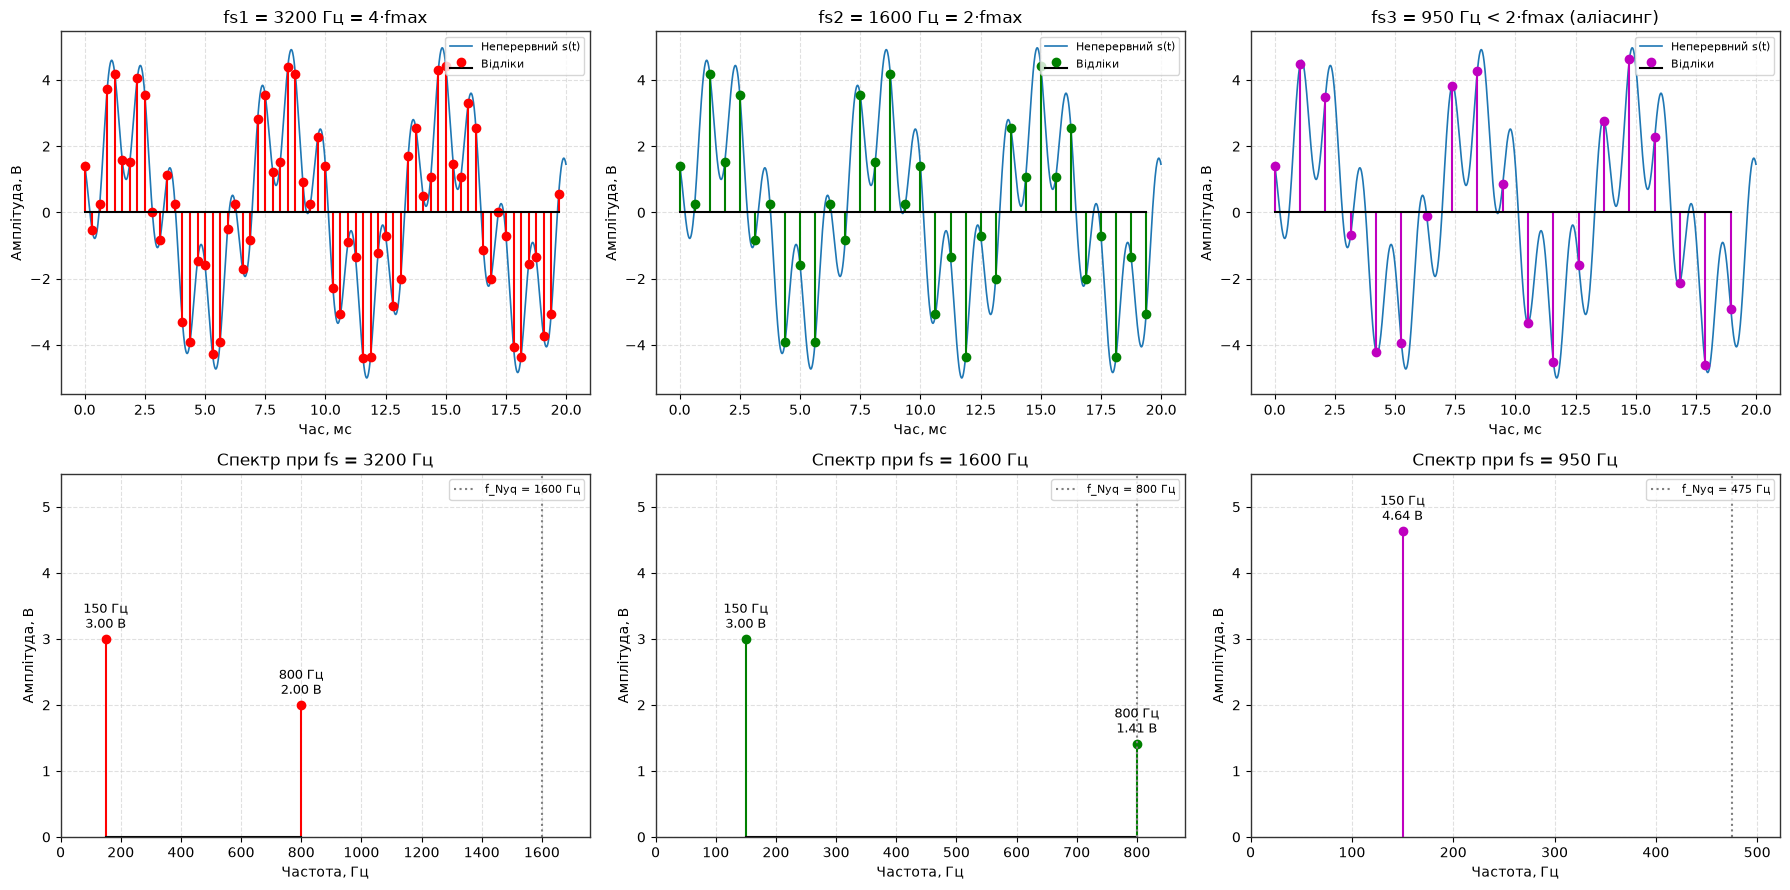

In [5]:
# короткий інтервал (для графіків у часі)
t_cont, s_cont = sample(fs_cont, T_obs)
t_s1, s_s1 = sample(f_s1, T_obs)
t_s2, s_s2 = sample(f_s2, T_obs)
t_s3, s_s3 = sample(f_s3, T_obs)

# довгий інтервал (для спектрів)
t_l1, s_l1 = sample(f_s1, T_long)
t_l2, s_l2 = sample(f_s2, T_long)
t_l3, s_l3 = sample(f_s3, T_long)


def compute_spectrum(x, fs):
    """Односторонній амплітудний спектр сигналу x (FFT)"""
    n_pts = len(x)
    X = rfft(x)
    freqs = rfftfreq(n_pts, 1.0 / fs)
    amp = 2.0 * np.abs(X) / n_pts
    amp[0] /= 2.0              # постійна складова
    if n_pts % 2 == 0:
        amp[-1] /= 2.0         # частота Найквіста не має дзеркального двійника
    return freqs, amp


spectra = {}
for name, fs, x in (("fs1", f_s1, s_l1), ("fs2", f_s2, s_l2), ("fs3", f_s3, s_l3)):
    fa, sp = compute_spectrum(x, fs)
    spectra[name] = (fa, sp)
    lines = np.where(sp > 0.05)[0]
    txt = ", ".join(f"{fa[i]:.0f} Гц ({sp[i]:.3f} В)" for i in lines)
    print(f"{name} = {fs:.0f} Гц: {txt}")

# перевірка амплітуд аналітично
# fs3: 800 Гц переходить у 150 Гц (f2 = fs3 - 150), тому cos(...+phi) -> cos(theta - phi)
# і складова на 150 Гц складається з sin- та cos-частин
a_sin = A1 + A2 * np.sin(phi)
a_cos = A2 * np.cos(phi)
print(f"Очікувана амплітуда на 150 Гц при fs3: {np.hypot(a_sin, a_cos):.3f} В")
# fs2: 800 Гц дорівнює частоті Найквіста, cos(pi*n + phi) = (-1)^n * cos(phi)
print(f"Очікувана амплітуда на 800 Гц при fs2: {A2 * abs(np.cos(phi)):.3f} В")

# графіки
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
cases = [
    ("fs1", f_s1, t_s1, s_s1, "r", f"fs1 = {f_s1:.0f} Гц = 4·fmax"),
    ("fs2", f_s2, t_s2, s_s2, "g", f"fs2 = {f_s2:.0f} Гц = 2·fmax"),
    ("fs3", f_s3, t_s3, s_s3, "m", f"fs3 = {f_s3:.0f} Гц < 2·fmax (аліасинг)"),
]
for col, (name, fs, t_d, s_d, c, title) in enumerate(cases):
    # верхній ряд - сигнал у часі
    ax = axes[0, col]
    ax.plot(t_cont * 1000, s_cont, color='#1f77b4', lw=1.2, label='Неперервний s(t)')
    ax.stem(t_d * 1000, s_d, linefmt=c + '-', markerfmt=c + 'o', basefmt='k-', label='Відліки')
    ax.set_title(title)
    ax.set_xlabel("Час, мс")
    ax.set_ylabel("Амплітуда, В")
    ax.grid(True)
    ax.legend(loc='upper right', fontsize=8)

    # нижній ряд - амплітудний спектр
    fa, sp = spectra[name]
    ax = axes[1, col]
    idx = np.where(sp > 1e-3)[0]
    ax.stem(fa[idx], sp[idx], linefmt=c + '-', markerfmt=c + 'o', basefmt='k-')
    for i in idx:
        ax.annotate(f"{fa[i]:.0f} Гц\n{sp[i]:.2f} В", (fa[i], sp[i]),
                    textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)
    ax.axvline(fs / 2, color='gray', ls=':', label=f"f_Nyq = {fs / 2:.0f} Гц")
    ax.set_xlim(0, 1.1 * fs / 2)
    ax.set_ylim(0, 5.5)
    ax.set_title(f"Спектр при fs = {fs:.0f} Гц")
    ax.set_xlabel("Частота, Гц")
    ax.set_ylabel("Амплітуда, В")
    ax.grid(True)
    ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig("figures/sampling_aliasing.png", dpi=300)
plt.show()

**Результати дискретизації** (спектри обчислено на інтервалі 1 с, роздільність 1 Гц):

| $f_s$, Гц | $f_{Nyq}$, Гц | Лінії спектра | Примітка |
|---|---|---|---|
| 3200 ($4 f_{max}$) | 1600 | 150 Гц — 3.00 В; 800 Гц — 2.00 В | спектр відповідає вихідному сигналу |
| 1600 ($2 f_{max}$) | 800 | 150 Гц — 3.00 В; 800 Гц — 1.41 В | друга гармоніка лежить на $f_{Nyq}$, видно $A_2 \cos(\pi/4) = 1.41$ В замість 2.00 В |
| 950 | 475 | 150 Гц — 4.64 В | 800 Гц переходить у 150 Гц і додається до першої гармоніки |

При $f_s = 2 f_{max}$ відліки другої гармоніки мають вигляд $A_2 \cos(\pi n + \varphi) = A_2 \cos\varphi \cdot (-1)^n$, тобто за ними визначається лише добуток $A_2 \cos\varphi$, а не амплітуда й фаза окремо.

При $f_s = 950$ Гц маємо $800 = 950 - 150$, тому $\cos(2\pi \cdot 800\, n / f_s + \varphi) = \cos(2\pi \cdot 150\, n / f_s - \varphi)$. Складова на 150 Гц дорівнює $(A_1 + A_2 \sin\varphi) \sin\theta + A_2 \cos\varphi \cos\theta$, її амплітуда $\sqrt{(A_1 + A_2 \sin\varphi)^2 + (A_2 \cos\varphi)^2} = \sqrt{13 + 6\sqrt{2}} \approx 4.64$ В, що збігається з результатом FFT.

### Блок 4. Квантування за рівнем, похибки та розрахунок SNR

Діапазон АЦП: [-5.0; 5.0] В, max|s| = 4.414 В, Ps = 6.500 В^2 (теор. (A1^2 + A2^2)/2 = 6.500)
--- РЕЗУЛЬТАТИ КВАНТУВАННЯ ЗА РІВНЕМ ---
  N      L   Delta, В  sigma_e^2, В^2   Delta^2/12   SNR, дБ  6.02N+1.76  Ps/(D^2/12)
  2      4   3.333333       8.742e-01    9.259e-01      8.71       13.80         8.46
  4     16   0.666667       3.485e-02    3.704e-02     22.71       25.84        22.44
  8    256   0.039216       1.363e-04    1.282e-04     46.79       49.92        47.05
 16  65536   0.000153       2.769e-09    1.940e-09     93.71       98.08        95.25


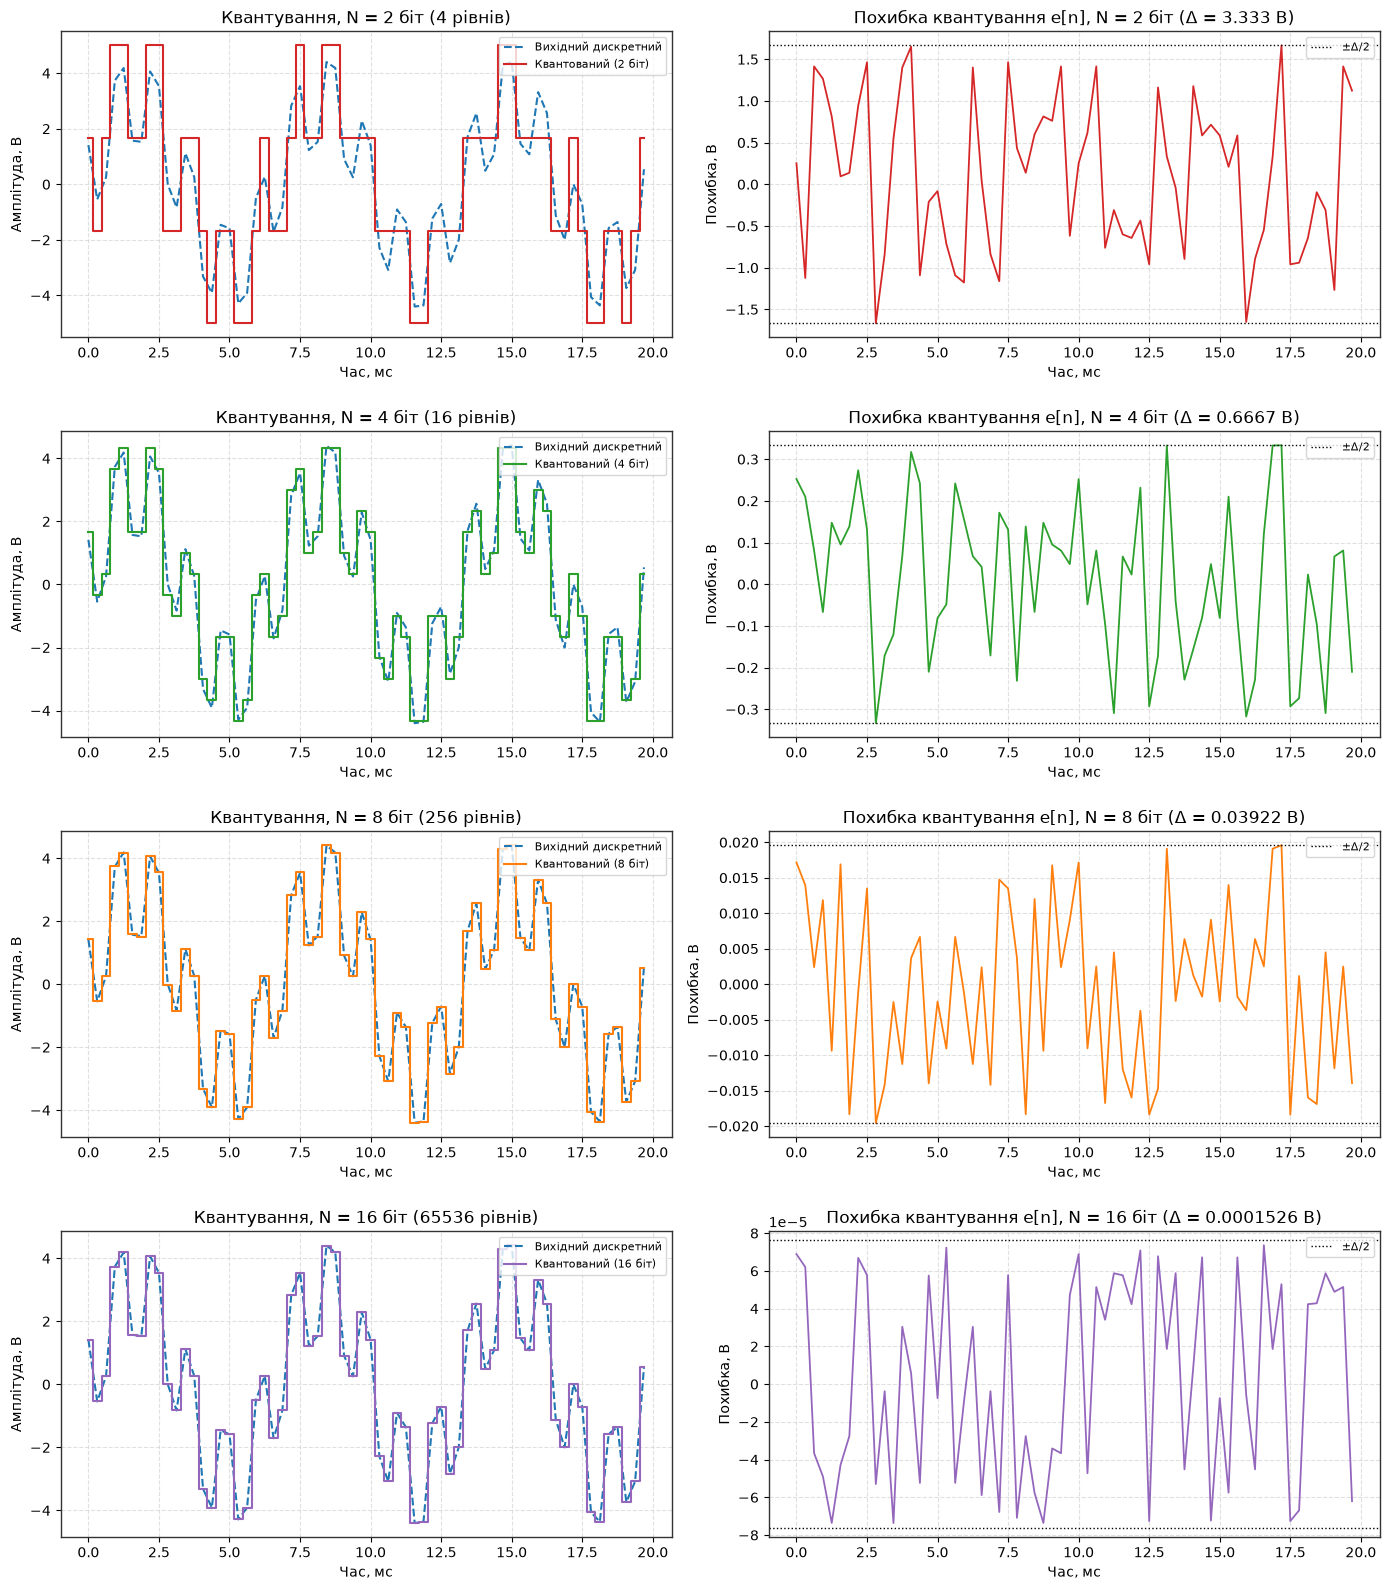

In [6]:
def uniform_quantize(x, bits, v_min, v_max):
    """Рівномірне квантування з округленням до найближчого рівня.
    Повертає квантований сигнал, похибку e = xq - x та крок Delta."""
    levels = 2 ** bits
    delta = (v_max - v_min) / (levels - 1)
    idx = np.round((x - v_min) / delta)
    idx = np.clip(idx, 0, levels - 1)       # захист від насичення
    xq = v_min + idx * delta
    return xq, xq - x, delta


def calc_snr(x, err):
    """Співвідношення сигнал/шум, дБ"""
    p_s = np.mean(x ** 2)
    p_e = np.mean(err ** 2)
    if p_e == 0:
        return float('inf')
    return 10.0 * np.log10(p_s / p_e)


bit_depths = [2, 4, 8, 16]
v_min, v_max = -5.0, 5.0          # діапазон АЦП, A1 + A2 = 5 В
p_signal = np.mean(s_l1 ** 2)     # потужність сигналу, В^2

quant = {}
print(f"Діапазон АЦП: [{v_min}; {v_max}] В, max|s| = {np.max(np.abs(s_l1)):.3f} В, "
      f"Ps = {p_signal:.3f} В^2 (теор. (A1^2 + A2^2)/2 = {(A1 ** 2 + A2 ** 2) / 2:.3f})")
print("--- РЕЗУЛЬТАТИ КВАНТУВАННЯ ЗА РІВНЕМ ---")
print(f"{'N':>3} {'L':>6} {'Delta, В':>10} {'sigma_e^2, В^2':>15} {'Delta^2/12':>12} "
      f"{'SNR, дБ':>9} {'6.02N+1.76':>11} {'Ps/(D^2/12)':>12}")
for bits in bit_depths:
    xq, err, delta = uniform_quantize(s_l1, bits, v_min, v_max)
    var_e = np.mean(err ** 2)
    snr = calc_snr(s_l1, err)
    snr_rule = 6.02 * bits + 1.76
    snr_exact = 10.0 * np.log10(p_signal / (delta ** 2 / 12.0))
    quant[bits] = {'xq': xq, 'err': err, 'delta': delta, 'var': var_e,
                   'snr': snr, 'snr_rule': snr_rule, 'snr_exact': snr_exact}
    print(f"{bits:3d} {2 ** bits:6d} {delta:10.6f} {var_e:15.3e} {delta ** 2 / 12:12.3e} "
          f"{snr:9.2f} {snr_rule:11.2f} {snr_exact:12.2f}")

# графіки: перші 64 відліки (20 мс) для кожної розрядності
n_show = len(t_s1)
t_ms = t_l1[:n_show] * 1000
colors = {2: '#d62728', 4: '#2ca02c', 8: '#ff7f0e', 16: '#9467bd'}

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for row, bits in enumerate(bit_depths):
    q = quant[bits]
    ax = axes[row, 0]
    ax.plot(t_ms, s_l1[:n_show], '--', color='#1f77b4', label='Вихідний дискретний')
    ax.step(t_ms, q['xq'][:n_show], where='mid', color=colors[bits],
            label=f'Квантований ({bits} біт)')
    ax.set_title(f"Квантування, N = {bits} біт ({2 ** bits} рівнів)")
    ax.set_xlabel("Час, мс")
    ax.set_ylabel("Амплітуда, В")
    ax.grid(True)
    ax.legend(loc='upper right', fontsize=8)

    ax = axes[row, 1]
    ax.plot(t_ms, q['err'][:n_show], color=colors[bits], lw=1.3)
    ax.axhline(q['delta'] / 2, color='k', ls=':', lw=1)
    ax.axhline(-q['delta'] / 2, color='k', ls=':', lw=1, label='±Δ/2')
    ax.set_title(f"Похибка квантування e[n], N = {bits} біт (Δ = {q['delta']:.4g} В)")
    ax.set_xlabel("Час, мс")
    ax.set_ylabel("Похибка, В")
    ax.grid(True)
    ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig("figures/quantization_error.png", dpi=300)
plt.show()

**Зведена таблиця параметрів квантування** (діапазон $[-5; 5]$ В, $P_s = 6.5$ В²):

| $N$ | $L = 2^N$ | $\Delta$, В | $\sigma_e^2$, В² (розрахунок) | $\Delta^2/12$, В² | SNR, дБ (розрахунок) | $6.02N + 1.76$, дБ | $10\lg\frac{P_s}{\Delta^2/12}$, дБ |
|---|---|---|---|---|---|---|---|
| 2 | 4 | 3.3333 | $8.742 \cdot 10^{-1}$ | $9.259 \cdot 10^{-1}$ | 8.71 | 13.80 | 8.46 |
| 4 | 16 | 0.6667 | $3.485 \cdot 10^{-2}$ | $3.704 \cdot 10^{-2}$ | 22.71 | 25.84 | 22.44 |
| 8 | 256 | 0.03922 | $1.363 \cdot 10^{-4}$ | $1.282 \cdot 10^{-4}$ | 46.79 | 49.92 | 47.05 |
| 16 | 65536 | 0.000153 | $2.769 \cdot 10^{-9}$ | $1.940 \cdot 10^{-9}$ | 93.71 | 98.08 | 95.25 |

Похибка квантування в усіх випадках не виходить за межі $\pm\Delta/2$ (пунктирні лінії на графіках). Збільшення розрядності на 1 біт дає приблизно +6 дБ до SNR: від $N = 4$ до $N = 8$ різниця становить 24.08 дБ (6.02 дБ/біт), від $N = 8$ до $N = 16$ — 46.92 дБ (5.87 дБ/біт).

Розрахункові значення SNR менші за $6.02N + 1.76$, бо цей вираз виведено для синуса на всю шкалу, а тут сигнал двотональний із $P_s = 6.5$ В² (повномасштабний синус з амплітудою 5 В мав би 12.5 В², різниця $10\lg(6.5/12.5) = -2.84$ дБ), та ще й $\Delta$ рахується як $(V_{max} - V_{min})/(2^N - 1)$. Із врахуванням реальної потужності сигналу (остання колонка) результати для $N = 2, 4, 8$ збігаються з розрахунком у межах 0.3 дБ. Для $N = 16$ розбіжність більша (93.71 проти 95.25 дБ): сигнал періодичний з періодом 20 мс (64 відліки), тому похибка набуває лише 64 різних значень і не є випадковою величиною з рівномірним розподілом.

### Блок 5. Дослідження дизеризації (Dithering)

Розрядність N = 3, Delta = 1.4286 В, A_d = 0.5*Delta = 0.7143 В
Без дизеризації:  SNR =  14.58 дБ, макс. лінія / середнє =  44.0 дБ
З дизеризацією:   SNR =  12.39 дБ, макс. лінія / середнє =  10.9 дБ
Дисперсія похибки: без дизеру 0.2265 В^2, з дизером 0.3751 В^2, Delta^2/12 = 0.1701 В^2


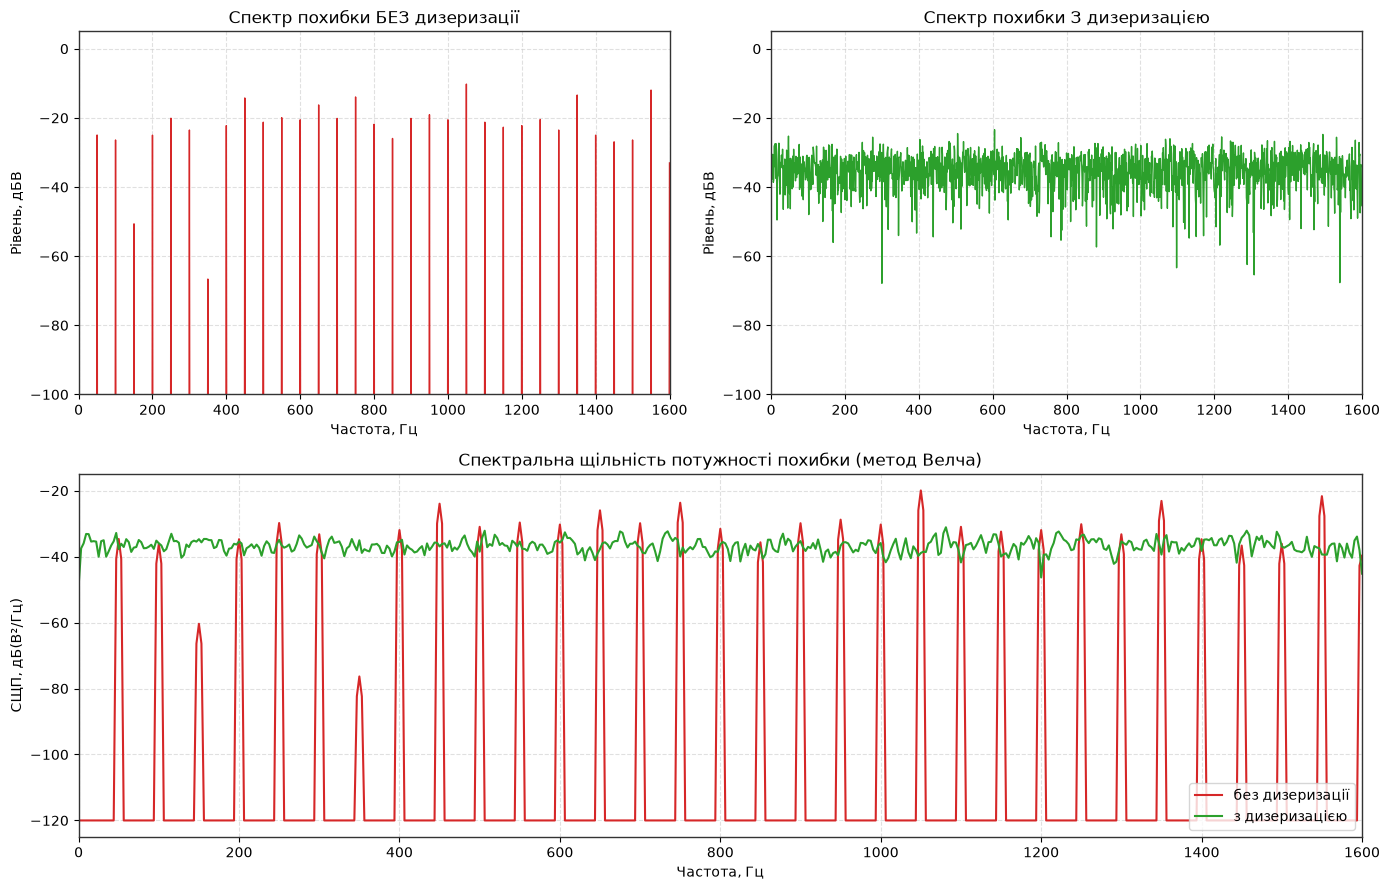

In [7]:
np.random.seed(42)      # щоб результат відтворювався

bits_d = 3                                       # груба розрядність, щоб ефект було видно
delta_d = (v_max - v_min) / (2 ** bits_d - 1)
A_d = 0.5 * delta_d                              # амплітуда дизер-шуму за варіантом

# квантування без дизеризації
xq_nd, err_nd, _ = uniform_quantize(s_l1, bits_d, v_min, v_max)

# квантування з дизеризацією: d[n] ~ U(-A_d, +A_d)
d = np.random.uniform(-A_d, A_d, size=len(s_l1))
xq_d, _, _ = uniform_quantize(s_l1 + d, bits_d, v_min, v_max)
err_d = xq_d - s_l1                               # похибка відносно чистого сигналу

snr_nd = calc_snr(s_l1, err_nd)
snr_d = calc_snr(s_l1, err_d)

# спектри похибок (FFT)
f_e1, sp_e1 = compute_spectrum(err_nd, f_s1)
f_e2, sp_e2 = compute_spectrum(err_d, f_s1)


def peak_to_mean(amp):
    """Найбільша спектральна лінія відносно середнього рівня спектра, дБ (без постійної складової)"""
    return 20.0 * np.log10(np.max(amp[1:]) / np.mean(amp[1:]))


# оцінка спектральної щільності потужності похибки (метод Велча)
f_w, psd_nd = signal.welch(err_nd, fs=f_s1, nperseg=1024)
_, psd_d = signal.welch(err_d, fs=f_s1, nperseg=1024)

print(f"Розрядність N = {bits_d}, Delta = {delta_d:.4f} В, A_d = 0.5*Delta = {A_d:.4f} В")
print(f"Без дизеризації:  SNR = {snr_nd:6.2f} дБ, "
      f"макс. лінія / середнє = {peak_to_mean(sp_e1):5.1f} дБ")
print(f"З дизеризацією:   SNR = {snr_d:6.2f} дБ, "
      f"макс. лінія / середнє = {peak_to_mean(sp_e2):5.1f} дБ")
print(f"Дисперсія похибки: без дизеру {np.mean(err_nd ** 2):.4f} В^2, "
      f"з дизером {np.mean(err_d ** 2):.4f} В^2, Delta^2/12 = {delta_d ** 2 / 12:.4f} В^2")

fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(2, 2)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1], sharey=ax1)
ax3 = fig.add_subplot(gs[1, :])

ax1.plot(f_e1, 20 * np.log10(np.maximum(sp_e1, 1e-6)), color='#d62728', lw=1.0)
ax1.set_title("Спектр похибки БЕЗ дизеризації")
ax2.plot(f_e2, 20 * np.log10(np.maximum(sp_e2, 1e-6)), color='#2ca02c', lw=1.0)
ax2.set_title("Спектр похибки З дизеризацією")
for ax in (ax1, ax2):
    ax.set_xlabel("Частота, Гц")
    ax.set_ylabel("Рівень, дБВ")
    ax.set_xlim(0, f_s1 / 2)
    ax.set_ylim(-100, 5)
    ax.grid(True)

# нижня межа -120 дБ, щоб нульові відрізки спектра не розтягували масштаб
ax3.plot(f_w, 10 * np.log10(np.maximum(psd_nd, 1e-12)), color='#d62728', label='без дизеризації')
ax3.plot(f_w, 10 * np.log10(np.maximum(psd_d, 1e-12)), color='#2ca02c', label='з дизеризацією')
ax3.set_title("Спектральна щільність потужності похибки (метод Велча)")
ax3.set_xlabel("Частота, Гц")
ax3.set_ylabel("СЩП, дБ(В²/Гц)")
ax3.set_xlim(0, f_s1 / 2)
ax3.grid(True)
ax3.legend(loc='lower right')

plt.tight_layout()
plt.savefig("figures/dither_spectrum.png", dpi=300)
plt.show()

**Результати дизеризації** ($N = 3$, $\Delta = 1.4286$ В, $A_d = 0.5\Delta = 0.7143$ В):

| | SNR, дБ | $\sigma_e^2$, В² | Максимальна лінія / середній рівень спектра, дБ |
|---|---|---|---|
| Без дизеризації | 14.58 | 0.2265 | 44.0 |
| З дизеризацією | 12.39 | 0.3751 | 10.9 |

Без дизеризації спектр похибки складається з окремих ліній на частотах, кратних 50 Гц (період сигналу 20 мс, бо НСД(150; 800) = 50 Гц), найвищі з них доходять приблизно до −10 дБВ. Це гармонічні та інтермодуляційні спотворення, шум квантування жорстко пов'язаний із сигналом. Після додавання дизер-шуму лінії зникають, а спектр похибки стає практично рівномірним (рівень близько −35 дБВ з випадковими коливаннями), що видно і на оцінці спектральної щільності потужності за методом Велча.

Ціною є зростання загальної потужності похибки: дисперсія збільшилась приблизно вдвічі (теоретично $\Delta^2/12 + \Delta^2/12 = \Delta^2/6 = 0.340$ В²), SNR зменшився на 2.2 дБ.

### Блок 6. Експорт числових масивів у CSV

In [8]:
export = [
    ("s_fs1", f_s1, s_l1),
    ("s_fs2", f_s2, s_l2),
    ("s_fs3", f_s3, s_l3),
]
for bits in bit_depths:
    export.append((f"xq_N{bits}", f_s1, quant[bits]['xq']))
    export.append((f"err_N{bits}", f_s1, quant[bits]['err']))
export.append((f"xq_N{bits_d}_no_dither", f_s1, xq_nd))
export.append((f"err_N{bits_d}_no_dither", f_s1, err_nd))
export.append((f"dither_N{bits_d}", f_s1, d))
export.append((f"xq_N{bits_d}_dither", f_s1, xq_d))
export.append((f"err_N{bits_d}_dither", f_s1, err_d))

with open("data/output_signals.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["signal", "n", "t_s", "value_V"])
    for name, fs, arr in export:
        for n, v in enumerate(arr):
            writer.writerow([name, n, f"{n / fs:.8f}", f"{v:.8f}"])

print(f"\nУ CSV записано {sum(len(a) for _, _, a in export)} рядків ({len(export)} сигналів).")
print("Моделювання завершено. Графіки збережено в 'figures/', дані - в 'data/'.")


У CSV записано 47350 рядків (16 сигналів).
Моделювання завершено. Графіки збережено в 'figures/', дані - в 'data/'.


У CSV записано 16 сигналів (47350 рядків) у форматі `signal, n, t_s, value_V`: відліки сигналу для трьох частот дискретизації, квантовані сигнали та похибки для $N = 2, 4, 8, 16$ і сигнали дослідження дизеризації ($N = 3$).

## 5. Висновки

1. При $f_{s1} = 3200$ Гц ($4 f_{max}$) у спектрі присутні лише дві лінії: 150 Гц (3.00 В) і 800 Гц (2.00 В). Умова теореми відліків виконується, сигнал дискретизується без втрати інформації.

2. При $f_{s2} = 1600$ Гц ($2 f_{max}$) гармоніка 800 Гц потрапляє точно на частоту Найквіста. У спектрі її амплітуда 1.41 В замість 2.00 В ($A_2 \cos\varphi$), тобто за відліками сигнал однозначно відновити неможливо. Тому на практиці частоту дискретизації вибирають із запасом, $f_s > 2 f_{max}$.

3. При $f_{s3} = 950$ Гц $< 2 f_{max}$ виникає аліасинг: гармоніка 800 Гц відображається на частоту $|800 - 950| = 150$ Гц, що збігається з аналітичним розрахунком і значенням із таблиці варіантів. Оскільки хибна частота збігається з $f_1$, складові додаються (амплітуда 4.64 В замість 3.00 В), і за спектром відрізнити псевдонім від справжньої гармоніки неможливо. Це обґрунтовує потребу антиаліасингового фільтра перед дискретизацією.

4. Квантування: крок $\Delta$ зменшується від 3.33 В ($N = 2$) до 0.000153 В ($N = 16$), похибка завжди лежить у межах $\pm\Delta/2$. SNR зростає приблизно на 6 дБ на кожен біт: з 8.71 дБ при $N = 2$ до 93.71 дБ при $N = 16$. Значення, розраховані за потужністю реального сигналу, добре узгоджуються з $10\lg(P_s/(\Delta^2/12))$; відставання від $6.02N + 1.76$ пояснюється тим, що сигнал не займає всю шкалу, як синус максимальної амплітуди.

5. Дизеризація з $A_d = 0.5\Delta$ при $N = 3$ прибирає лінійчаті спотворення в спектрі похибки (відношення найвищої лінії до середнього рівня зменшилось з 44.0 до 10.9 дБ) і робить шум квантування близьким до білого. Ціною цього є менший SNR (12.39 дБ проти 14.58 дБ).

## Відповідь на контрольні питання

**1. У чому полягає фізичний і математичний зміст теореми відліків Котельникова-Шеннона-Найквіста, та чому для практичних застосувань частоту дискретизації обирають із запасом $f_s \approx (2.5 \dots 4) f_{max}$?**

* **Математичний зміст:** Будь-який неперервний сигнал з обмеженим спектром, що не містить частот вище $f_{max}$, може бути однозначно та без втрат відновлений за своїми дискретними відліками, узятими через рівні проміжки часу $T_s = \frac{1}{f_s}$, за умови $f_s > 2 f_{max}$. Відновлення здійснюється за допомогою ряду Віттекера — Шеннона (інтерполяцією функціями $\text{sinc}$):

$$x(t) = \sum_{n=-\infty}^{\infty} x[n] \cdot \text{sinc}\left(\frac{t - nT_s}{T_s}\right)$$


* **Фізичний зміст:** Дискретизація в часі призводить до періодичного розмноження спектра сигналу в частотній області з періодом $f_s$. Умова $f_s > 2 f_{max}$ гарантує, що сусідні копії спектра не перекриваються, і вихідний спектр можна виділити ідеальним фільтром нижніх частот із частотою зрізу $f_N = f_s / 2$ (частота Найквіста). На рівні часової форми це означає, що на кожен період найбільш високочастотної гармоніки має припадати більше двох відліків.
* **Чому беруть запас $f_s \approx (2.5 \dots 4) f_{max}$:**
1. **Неідеальність реальних фільтрів:** Ідеальний фільтр із вертикальною АЧХ фізично нереалізовний. Реальні аналогові згладжувальні фільтри мають скінченну крутість спаду в перехідній смузі, тому між $f_{max}$ та $f_s/2$ потрібен частотний зазор, щоб придушити завади до рівня нижче шуму квантування.
2. **Скінченна тривалість сигналів:** Реальні сигнали обмежені в часі, тому їхній спектр теоретично нескінченний і містить спадні хвости вище $f_{max}$.
3. **Точність відновлення в часі:** При $f_s \approx 2 f_{max}$ відліки можуть потрапити поблизу нулів синусоїди, через що для точного відновлення амплітуди та фази знадобляться фільтри надвисокого порядку зі значною затримкою.



---

**2. Який механізм виникнення ефекту аліасингу (стробоскопічного накладання частот), та за якою формулою визначається частота хибної гармоніки $f_{alias}$ у разі порушення умови теореми відліків?**

* **Механізм виникнення:** У частотній області дискретизація являє собою згортку спектра неперервного сигналу з періодичною послідовністю імпульсів із кроком $f_s$. У результаті спектр періодично копіюється навколо кожної гармоніки частоти дискретизації $k \cdot f_s$ ($k = \pm 1, \pm 2, \dots$). Якщо в сигналі присутня складова з частотою $f > f_s/2$ (порушено теорему відліків), верхня межа основного спектра накладається на нижню межу зміщеної копії спектра. У часовій області це аналогічно стробоскопічному ефекту: рідкісні відліки «перестрибують» через періоди швидкої гармоніки та формують хибну низькочастотну синусоїду.
* **Формула частоти хибної гармоніки:** Частота $f_{alias}$, що потрапляє в основну смугу Найквіста $[0, f_s/2]$, визначається як відстань від вихідної частоти $f$ до найближчої цілої кратної частоти дискретизації $k \cdot f_s$:

$$f_{alias} = \vert{}f - k \cdot f_s\vert{}$$



де $k = \text{round}\left(\frac{f}{f_s}\right)$ — ціле число, яке обирається так, щоб виконувалася умова $0 \le f_{alias} \le \frac{f_s}{2}$.

---

**3. Чому перед блоком вибірки та зберігання в реальних аналого-цифрових перетворювачах обов'язково встановлюється аналоговий фільтр захисту від аліасингу (Anti-Aliasing Filter), і яку частоту зрізу він повинен мати?**

* **Навіщо він встановлюється:** Після того як сигнал пройшов через пристрій вибірки та зберігання (ПВЗ) і був дискретизований за часом, високочастотні складові ($f > f_s/2$) вже наклалися на корисний діапазон частот $[0, f_s/2]$. Цифровими фільтрами після АЦП відрізнити хибну гармоніку (аліас) від істинного корисного сигналу тієї ж частоти принципово неможливо. Тому всі складові вище частоти Найквіста необхідно придушити до дискретизації, тобто в аналоговому тракті перед ПВЗ.
* **Необхідна частота зрізу:** Частота зрізу аналогового фільтра захисту від аліасингу $f_c$ повинна бути строго меншою за половину частоти дискретизації (частоти Найквіста):

$$f_{max} \le f_c < \frac{f_s}{2}$$



На практиці $f_c$ обирають на верхній межі смуги корисного сигналу ($f_c \approx f_{max}$), причому до частоти Найквіста $f_s/2$ перехідна характеристика фільтра повинна ослаблювати завади до рівня шумової полиці АЦП (зазвичай на $60\text{–}90\text{ дБ}$).

---

**4. Як пов'язані між собою крок рівномірного квантування $\Delta$, розрядність АЦП $N$ та динамічний діапазон вхідного аналогового сигналу $[V_{min}, V_{max}]$?**

При розрядності АЦП $N$ біт уся шкала перетворення ділиться на $2^N$ дискретних рівнів. Крок рівномірного квантування $\Delta$ (величина молодшого значущого біта, $\text{LSB}$) дорівнює відношенню повного динамічного діапазону вхідної напруги $V_{FS} = V_{max} - V_{min}$ до кількості рівнів квантування:

$$\Delta = \frac{V_{max} - V_{min}}{2^N}$$

---

**5. Звідки береться емпіричне правило «+6 дБ на кожен додатковий біт розрядності» при розрахунку співвідношення сигнал/шум ($\text{SNR}$)?**

При рівномірному квантуванні похибка квантування моделюється як рівномірно розподілений білий шум в інтервалі $[-\Delta/2, +\Delta/2]$, середня потужність якого дорівнює:

$$P_{noise} = \frac{\Delta^2}{12}$$

Для гармонічного сигналу на повну шкалу з амплітудою $A = \frac{V_{FS}}{2} = \frac{2^N \Delta}{2} = 2^{N-1}\Delta$ середня потужність сигналу становить:

$$P_{signal} = \frac{A^2}{2} = \frac{(2^{N-1}\Delta)^2}{2} = \frac{2^{2N} \Delta^2}{8}$$

Відношення потужностей сигналу та шуму (теоретичний максимум $\text{SNR}$ ідеального $N$-бітного АЦП):

$$\text{SNR} = \frac{P_{signal}}{P_{noise}} = \frac{2^{2N} \Delta^2 / 8}{\Delta^2 / 12} = \frac{3}{2} \cdot 2^{2N}$$

У децибелах цей вираз набуває вигляду:

$$\text{SNR}_{\text{дБ}} = 10 \log_{10}\left(\frac{3}{2} \cdot 2^{2N}\right) = 10 \log_{10}(1.5) + 20 N \log_{10}(2) \approx 1.76 + 6.02 \cdot N \text{ (дБ)}$$

Множник $20 \log_{10}(2) \approx 6.02\text{ дБ}$ перед $N$ показує, що кожен додатковий біт удвічі зменшує крок квантування $\Delta$, у $4$ рази знижує потужність шуму квантування і тим самим збільшує $\text{SNR}$ приблизно на $6\text{ дБ}$.

---

**6. Чому при малих розрядностях квантування ($N \le 4$) виникають нелінійні гармонійні спотворення, і яким чином додавання псевдовипадкового шуму (дизеризація) дозволяє усунути кореляцію між похибкою квантування та вхідним сигналом?**

* **Причина нелінійних спотворень:** Квантування є нелінійною східчастою операцією. Модель білого шуму для похибки квантування справедлива лише тоді, коли сигнал перетинає багато рівнів. При малій розрядності ($N \le 4$) крок $\Delta$ є великим: плавно змінний або слабкий сигнал «застрягає» на кількох сходинках, і похибка квантування $e[n] = x_q[n] - x[n]$ стає детермінованою періодичною функцією вхідного сигналу. У спектрі це проявляється у вигляді виражених дискретних гармонік (нелінійних спотворень), кратних частоті сигналу.
* **Механізм роботи дизеризації (dithering):** Перед квантуванням до аналогового сигналу підмішується слабкий псевдовипадковий шум $d[n]$ із розмахом порядку $0.5\text{–}1\,\text{LSB}$ (наприклад, із трикутним розподілом щільності ймовірності). Випадкові флуктуації змушують миттєві значення сигналу постійно перетинати пороги спрацьовування компараторів АЦП випадковим чином. У результаті похибка квантування декорелюється від корисного сигналу, дискретні паразитні гармоніки руйнуються та перетворюються на статистично незалежний білий шум, а середнє значення вихідного коду лінійно відстежує вхідний сигнал навіть при амплітудах менших за $\Delta$.

---

**7. У чому полягає відмінність між простою дизеризацією (неслідкуючою) та дизеризацією з відніманням (subtractive dither)?**

* **Проста (невіднімана / неслідкуюча) дизеризація (Non-Subtractive Dither, NSD):** Псевдовипадковий шум $d[n]$ додається до сигналу перед квантуванням ($x_q[n] = Q(x[n] + d[n])$), але не віднімається з цифрового коду після квантування. Метод простий у реалізації, проте призводить до зростання загальної потужності шуму на виході (при оптимальному трикутному дизерингу шумова полиця підвищується на $4.77\text{ дБ}$ відносно чистого шуму квантування).
* **Дизеризація з відніманням (Subtractive Dither, SD):** Та сама відома псевдовипадкова послідовність $d[n]$, яка була додана перед квантуванням, у цифровому вигляді віднімається з результату після квантування:

$$y[n] = Q(x[n] + d[n]) - d[n]$$



Цей метод вимагає суворої синхронізації генераторів шуму на вході та виході, однак дозволяє повністю усунути нелінійні спотворення без збільшення дисперсії вихідного шуму — підсумкова похибка $y[n] - x[n]$ строго дорівнює білому шуму з мінімальною дисперсією $\Delta^2 / 12$.